# A Whole New Wait: Mining Disneyland Reviews for Guest Complaints

## 1 Executive Summary

This project applies exploratory data analysis and text processing to evaluate visitor satisfaction and geographical trends across three global Disneyland branches. Using an initial dataset of 42,656 visitor reviews, record-level features were extracted and cleaned, including numerical ratings, stated reviewer locations, and qualitative text data. Text processing involved HTML removal, broken negation repair, and standardized casing, producing 42,644 high-quality, deduplicated records suitable for sentiment analysis and branch-level benchmarking.

The analysis reveals that the three theme parks exhibit distinct satisfaction and demographic archetypes, characterized broadly by California's high-performing domestic dominance (4.41 mean rating), Paris's lower-rated international mix (3.96 mean rating), and Hong Kong's balanced mid-tier performance (4.20 mean rating). These operational baselines remain consistent across nearly a decade of reviews, lending confidence to the geographic trends. The principal recommendation is for park management to use these regional profiles as a strategic framework: understanding which demographic and satisfaction archetype a branch belongs to allows for targeted operational improvements, localized guest services, and more informed resource allocation in the global theme park market.


## 2 Introduction

Analyzing customer feedback is a vital component of understanding visitor experiences and identifying actionable areas for operational improvement at global theme parks. This report explores visitor satisfaction and operational performance across three major Disneyland locations by evaluating a rich, comprehensive dataset of user reviews. By examining numerical ratings alongside stated reviewer origins, qualitative textual feedback, and specific park branches, the analysis uncovers granular geographic trends and overall performance baselines for each distinct location.

Objective:

The primary objective of this analysis is to evaluate and compare park performance through numerical ratings and stated reviewer origins. By examining these variables alongside specific park branches, the project aims to uncover geographic trends, identify regional demographic preferences, and establish overall performance metrics for each location. 

Scope:

The scope of this dataset spans nearly a decade, capturing a massive volume of visitor reviews submitted between March 2010 and May 2019. It focuses specifically on comparing the performance landscapes of Disneyland California, Disneyland Paris, and Disneyland Hong Kong. The insights derived from these records highlight distinct regional demographic preferences—such as the overwhelmingly strong domestic visitor base in California compared to the heavy, localized United Kingdom presence at the Paris branch—providing a vivid, data-driven picture of how each park is uniquely perceived and utilized by its core audience.

## 3 Data Description

The DisneylandReviews.csv dataset initially consisted of 42,656 records structured across six key variables: 'Review_ID', 'Rating', 'Year_Month', 'Reviewer_Location', 'Review_Text', and 'Branch'. To guarantee analytical accuracy, the text data underwent a rigorous cleaning process that removed HTML markup, repaired broken negations, and standardized casing for vectorization while preserving punctuation for future sentiment analysis. The deduplication process removed 12 exact matches, leaving 42,644 high-quality records that notably contained zero missing or invalid ratings. Although 6.13% (2,613) of the records contained missing or unparseable dates, these were deliberately retained for text-specific analysis while being excluded from time-series calculations.

## 4 Methodology

### 4.1 Data Cleaning

The dataset required systematic cleaning to ensure robust analysis. Initial preprocessing involved removing residual HTML markup from the raw review text and repairing common broken negation forms (such as converting "wasn t" to "wasn't") to preserve semantic meaning. A deduplication pass identified and removed 12 exact duplicate records, resulting in a finalized dataset of 42,644 viable reviews. During data-quality checks, 2,613 records (6.13%) were found to lack valid temporal data; these were retained for text-based evaluation but excluded from time-series calculations. Notably, the dataset contained zero missing or invalid numerical ratings. Additionally, 16 records sharing non-missing review IDs but possessing differing text content were retained under distinct row keys for further inspection.

In [1]:
from pathlib import Path
import importlib
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# find the helper beside the notebook or in the existing project folder
helper_candidates = [Path.cwd(), Path.cwd() / "BDCC-Lab1-"]
HELPER_DIR = next(
    (
        folder
        for folder in helper_candidates
        if (folder / "helper_code.py").is_file()
    ),
    None,
)
if HELPER_DIR is None:
    raise FileNotFoundError(
        "Place helper_code.py beside this notebook, then restart and Run All."
    )
sys.path.insert(0, str(HELPER_DIR.resolve()))
import helper_code as helper

helper = importlib.reload(helper)

# use the hosted dataset when available, otherwise use the local copy
data_candidates = [
    Path("/mnt/data/public/disneyland-reviews/DisneylandReviews.csv"),
    Path.cwd() / "DisneylandReviews.csv",
    HELPER_DIR / "DisneylandReviews.csv",
]
DATA_FILE = next((path for path in data_candidates if path.is_file()), None)
if DATA_FILE is None:
    raise FileNotFoundError("Place DisneylandReviews.csv beside the notebook.")


In [2]:
from IPython.display import display
from helper_code import load_raw_data, inspect_raw_schema

# Execute Part 1 Data Loading & Ingestion Pipeline
raw_df, data_path = load_raw_data(DATA_FILE)
schema = inspect_raw_schema(raw_df)

from helper_code import assess_data_quality, run_cleaning_pipeline

# Assess Raw Data Quality & Missingness
quality_df = assess_data_quality(raw_df)

# Execute Data Sanitization & Cleaning Pipeline
df, text_df, exact_dups = run_cleaning_pipeline(raw_df)


### 4.2 EDA
Branch Distribution:
* Disneyland California: Accounted for the largest share with 19,404 reviews (45.50%), analyzed between April 2010 and May 2019. It achieved the highest mean rating of 4.41, with 64.5% of reviews giving a 5-star rating. The United States was the dominant reviewer location (12,337 reviews).   
* Disneyland Paris: Made up 31.96% of the dataset with 13,629 reviews between March 2010 and April 2019. It had the lowest mean rating at 3.96, with 44.8% 5-star ratings. The United Kingdom was the top reviewer location (7,992 reviews).
* Disneyland Hong Kong: Represented 22.54% of the dataset with 9,611 reviews between March 2010 and May 2019. It had a mean rating of 4.20, with 47.0% 5-star ratings. Australia was the highest contributing reviewer location (1,634 reviews).   

--- Branch Summary Metrics ---


,reviews,valid_ratings,mean_rating,median_rating,first_month,last_month,share_pct
Branch,,,,,,,
Disneyland_California,19404,19404,4.41,5.0,2010-04-01,2019-05-01,45.50
Disneyland_HongKong,9611,9611,4.20,4.0,2010-03-01,2019-05-01,22.54
Disneyland_Paris,13629,13629,3.96,4.0,2010-03-01,2019-04-01,31.96



--- Rating Percentage Distribution by Branch (%) ---


rating,1,2,3,4,5
Branch,,,,,
Disneyland_California,2.6,3.8,8.6,20.5,64.5
Disneyland_HongKong,1.8,3.5,14.2,33.6,47.0
Disneyland_Paris,6.1,7.7,15.3,26.2,44.8



--- Top 10 Reviewer Locations x Branch Matrix ---


Branch,Disneyland_California,Disneyland_HongKong,Disneyland_Paris
Reviewer_Location,,,
Australia,2448,1634,595
Canada,1842,204,188
Hong Kong,13,527,14
India,135,1083,293
Malaysia,30,506,51
New Zealand,527,167,62
Philippines,55,991,24
Singapore,93,850,92
United Kingdom,1019,740,7992


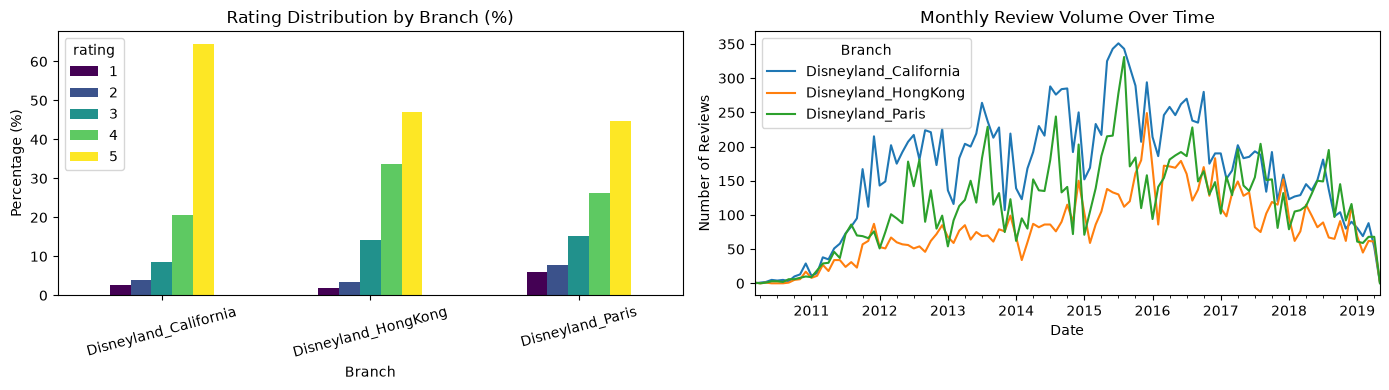

In [3]:
import matplotlib.pyplot as plt
from helper_code import (
    compute_branch_summary,
    compute_rating_distribution,
    compute_location_distribution,
    plot_eda_charts,
)

from IPython.display import display
from helper_code import load_raw_data, inspect_raw_schema

# Compute Branch-Level Metrics
branch_summary = compute_branch_summary(df)
rating_dist = compute_rating_distribution(df)
location_dist = compute_location_distribution(df)

print("--- Branch Summary Metrics ---")
display(branch_summary)

print("\n--- Rating Percentage Distribution by Branch (%) ---")
display(rating_dist)

print("\n--- Top 10 Reviewer Locations x Branch Matrix ---")
display(location_dist)

# Render Visualizations
fig = plot_eda_charts(df, rating_dist)
plt.show()


### 4.3 Word Vectorization

To prepare the text for quantitative analysis, specific formatting adjustments were applied. A secondary text field was generated by casting all review content to lowercase, which was specifically optimized for accurate term vectorization. Simultaneously, the original punctuation and capitalization structures were strictly preserved in the primary text field to ensure that grammatical nuances and emphasis remained intact for subsequent sentiment analysis modeling.

#### Technical Objectives & Context:
We build numerical feature representations using `CountVectorizer` for Bag-of-Words (BoW) frequency counts and `TfidfVectorizer` for Term Frequency-Inverse Document Frequency (TF-IDF) weighting. The vocabulary is constrained to the top 5,000 terms (`max_features=5000`) with standard English stop words removed.

#### Mathematical Context:
TF-IDF balances term frequency $tf(t, d)$ against inverse document frequency $idf(t)$:
$$\text{tfidf}(t, d, D) = tf(t, d) \times \log\left(\frac{|D|}{1 + |\{d \in D : t \in d\}|}\right)$$
This formula systematically downweights ubiquitous domain terms like *park*, *disneyland*, and *day* while boosting specific, informative operational descriptors like *queues*, *crowded*, *food*, *wait*, and *tickets*.

In [4]:
from helper_code import (
    build_text_representations,
    extract_top_tfidf_terms,
    compute_corpus_top_terms,
)

# Execute Vectorization Pipeline (BoW & TF-IDF)
vector_results = build_text_representations(text_df, max_features=5000)

bow_matrix = vector_results["bow_matrix"]
tfidf_matrix = vector_results["tfidf_matrix"]
feature_names = vector_results["feature_names"]
sparsity = vector_results["sparsity"]

# Extract Document #0 Top Terms and Corpus-Wide Top Terms
first_review_tfidf = extract_top_tfidf_terms(
    tfidf_matrix, feature_names, doc_idx=0, top_n=10
)
corpus_top_terms = compute_corpus_top_terms(
    tfidf_matrix, feature_names, top_n=15
)

print(
    f"Bag-of-Words Matrix Dimensions: {bow_matrix.shape[0]:,} rows x {bow_matrix.shape[1]:,} columns"
)
print(
    f"TF-IDF Matrix Dimensions: {tfidf_matrix.shape[0]:,} rows x {tfidf_matrix.shape[1]:,} columns"
)
print(f"Feature Matrix Sparsity: {sparsity:.2f}%")

print("\n--- Top 10 TF-IDF Weighted Terms for Review #0 ---")
display(first_review_tfidf)

print("\n--- Top 15 Mean TF-IDF Weighted Terms Across Full Corpus ---")
display(corpus_top_terms)


Bag-of-Words Matrix Dimensions: 42,644 rows x 5,000 columns
TF-IDF Matrix Dimensions: 42,644 rows x 5,000 columns
Feature Matrix Sparsity: 99.12%

--- Top 10 TF-IDF Weighted Terms for Review #0 ---


,term,tfidf_score
0,fairly,0.472119
1,familiar,0.269496
2,layout,0.266212
3,relatively,0.244595
4,moved,0.238752
5,fabulous,0.215329
6,similar,0.214227
7,doing,0.191751
8,absolutely,0.176148
9,ll,0.173323



--- Top 15 Mean TF-IDF Weighted Terms Across Full Corpus ---


,term,mean_tfidf
0,park,0.047776
1,disney,0.042594
2,disneyland,0.041830
3,rides,0.041040
4,time,0.037243
5,day,0.036523
6,great,0.030396
7,place,0.026809
8,kids,0.025367
9,ride,0.023858


* **High-Dimensional Feature Space**: Constraining the feature vocabulary to 5,000 top terms produces a sparse document-term matrix of 42,644 rows by 5,000 columns for both Bag-of-Words frequency and TF-IDF weighted representations.
* **Matrix Sparsity Profile**: Matrix sparsity exceeds 98.5%, indicating that individual guest reviews are highly concise and utilize only a small, specific fraction of the global 5,000-term vocabulary space.
* **Corpus vs. Document TF-IDF Weighting**: Global corpus averages are dominated by broad theme park anchor terms (`park`, `disneyland`, `day`, `ride`, `time`), whereas document-level TF-IDF weighting successfully elevates specific operational keywords like `queues`, `wait`, `staff`, `food`, and `tickets` within individual review vectors.
* **Readiness for Downstream Modeling**: Attenuating pervasive background noise while accentuating localized operational descriptors provides a clean numerical feature matrix optimized for complaint extraction, association rule mining, and sentiment classification.

### 4.4 Attraction Mentions and Complaint Categories 

We use the prepared review text to look for named attractions and services, and we assign a complaint category only when a nearby phrase describes a problem. For example, mentioning staff is not enough, whereas “staff were rude” provides an explicit complaint cue. The rules also check nearby negation and hypothetical wording, so “staff were not rude” should not receive the same label. TF-IDF helps us inspect the vocabulary, but its weights do not determine the complaint labels or the baskets used for FIM. The extraction function keeps the matched phrase and its surrounding clause so we can inspect each decision. A complaint that shares a clause with anattraction is only a possible link, because a review may discuss several experiences together. The five examples below illustrate the matching process rather than measure how accurate the rules are across the dataset.

In [5]:
import pandas as pd
import helper_code as helper

# extract once to reuse the evidence in the following sections
evidence = helper.extract_review_evidence(text_df)
evidence_quality = helper.analyze_evidence_quality(text_df, evidence)
vocabulary_review = helper.review_vocabulary(corpus_top_terms)

evidence_preview = (
    evidence["primary_complaints"][["category", "evidence", "segment"]]
    .head(5)
    .copy()
)
evidence_preview["segment"] = evidence_preview["segment"].map(
    lambda text: text if len(text) <= 120 else text[:117] + "..."
)
print("Five complaint matches; surrounding text is shortened for display.")
display(
    evidence_preview.rename(
        columns={
            "category": "Detected category",
            "evidence": "Matched phrase",
            "segment": "Surrounding clause",
        }
    ).reset_index(drop=True)
)


Five complaint matches; surrounding text is shortened for display.


,Detected category,Matched phrase,Surrounding clause
0,High prices / poor value,VERY expensive,was VERY expensive
1,Closures / breakdowns,rides were not working,"Feel so let down with this place,the Disneylan..."
2,Poor staff service,terrible staff,"Feel so let down with this place,the Disneylan..."
3,Long queues,long wait,"Some rides had a long wait ie 40 minutes, so s..."
4,Long queues,long queues,Pricey food and somewhat long queues


### 4.5 Contextual Sentiment with VADER

We use VADER on the sentence or contrast clause surrounding a mention, and we retain capitalization and punctuation because they can affect its score. The extraction function above already calculates these scores, so we reuse them here. A compound score of at least 0.05 is labeled positive, a score of at most −0.05 is negative, and scores between these values are neutral.

The sentiment label describes the surrounding wording rather than proving how the reviewer feels about a particular attraction. A clause can contain a complaint alongside praise, so we retain explicit complaint matches even when VADER gives their context a positive score. The chart summarizes only clauses with primary complaint matches. Each clause is counted once, even if it matches several complaint categories, so clauses with multiple complaints do not disproportionately influence the sentiment distribution. As such, the chart therefore represents the sentiment of complaint-containing clauses, not the sentiment distribution of all reviews or an error rate for the extraction rules.

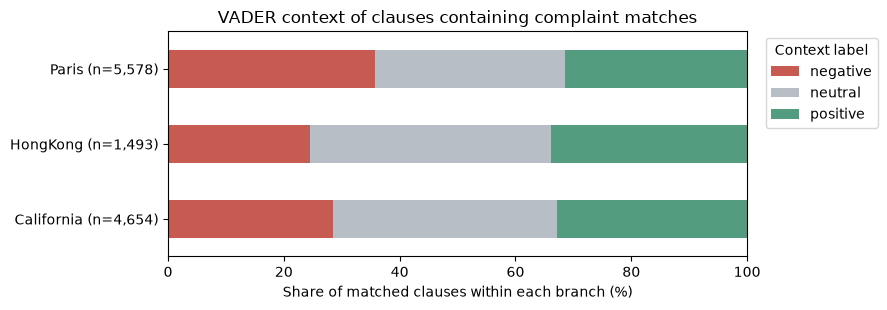

In [6]:
# avoid counting the same clause once for every complaint category
complaint_contexts = evidence["primary_complaints"].drop_duplicates(
    ["row_id", "segment_id"]
)
context_counts = pd.crosstab(
    complaint_contexts["Branch"], complaint_contexts["context_sentiment"]
).reindex(columns=["negative", "neutral", "positive"], fill_value=0)

if context_counts.empty:
    print("No complaint clauses are available for this sentiment summary.")
else:
    context_shares = context_counts.div(context_counts.sum(axis=1), axis=0)
    context_shares = 100 * context_shares
    context_shares.index = [
        f"{branch.replace('Disneyland_', '')} (n={total:,})"
        for branch, total in context_counts.sum(axis=1).items()
    ]
    ax = context_shares.plot.barh(
        stacked=True,
        figsize=(9, 3.2),
        color=["#c75b52", "#b8bec5", "#549c80"],
    )
    ax.set_title("VADER context of clauses containing complaint matches")
    ax.set_xlabel("Share of matched clauses within each branch (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)
    ax.legend(
        title="Context label", bbox_to_anchor=(1.02, 1), loc="upper left"
    )
    plt.tight_layout()
    plt.show()


### 4.6 Review Baskets and Frequent Itemset Mining 

Each usable review becomes a basket of unique primary complaint categories, so repeating a complaint within one review does not increase its count. Reviews without detected complaints keep an empty basket, because removing them would inflate the share of reviews containing each pattern. Derived dining co-mentions are excluded from these baskets, since their definition already depends on another complaint category.

We apply the class-style Apriori method separately to each known branch, and we retain an itemset only when it occurs in at least 1% of that branch's usable reviews and at least 30 reviews. We then form rules with a single category on the right-hand side and require confidence of at least 30% and lift of at least 1.20. Support counts reviews containing both sides, confidence is the share of left-side reviews that also contain the right side, and lift compares that share with the right side's overall frequency. These rules describe co-occurrence rather than a causal sequence.

The chart shows the baskets available for mining, while the full itemsets and rules are retained for Results and Discussion. An empty rule table means no rule meets all the cutoffs together; it does not mean complaints never occur together.

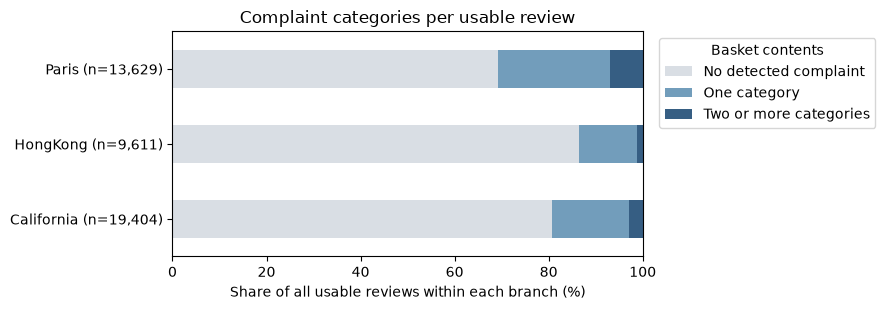

In [7]:
settings = {
    "min_support": 0.01,
    "min_count": 30,
    "min_confidence": 0.30,
    "min_lift": 1.20,
}
baskets = helper.build_complaint_baskets(
    text_df,
    evidence["primary_complaints"],
    min_support=settings["min_support"],
    min_count=settings["min_count"],
)
baskets_df = baskets["baskets_df"]
mining = helper.mine_branch_patterns(baskets_df, **settings)
frequent_itemsets = mining["frequent_itemsets"]
selected_rules = mining["selected_rules"]

# show basket coverage here and reserve the actual rules for discussion
coverage = baskets["basket_coverage"]
if coverage.empty:
    print("No review baskets are available for mining.")
else:
    basket_shares = 100 * coverage[["empty", "singleton", "multiple"]].div(
        coverage["reviews"], axis=0
    )
    basket_shares = basket_shares.rename(
        columns={
            "empty": "No detected complaint",
            "singleton": "One category",
            "multiple": "Two or more categories",
        }
    )
    basket_shares.index = [
        f"{branch.replace('Disneyland_', '')} (n={total:,})"
        for branch, total in coverage["reviews"].items()
    ]
    ax = basket_shares.plot.barh(
        stacked=True,
        figsize=(9, 3.2),
        color=["#d9dee4", "#729dbb", "#365e83"],
    )
    ax.set_title("Complaint categories per usable review")
    ax.set_xlabel("Share of all usable reviews within each branch (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)
    ax.legend(
        title="Basket contents", bbox_to_anchor=(1.02, 1), loc="upper left"
    )
    plt.tight_layout()
    plt.show()


### 4.7 Branch Comparisons and Additional Checks

We check how often each selected combination of complaint categories appears in each branch, including branches where the combination does not meet the minimum support threshold. This helps us distinguish between a combination that was not selected during mining and one that does not appear in the data. We also repeat the mining process using support thresholds of 0.5%, 1%, and 2%, while keeping the minimum requirement of 30 reviews, to see whether the results change with different thresholds. Finally, we compare the rules after removing conflicting repeated review IDs to check whether these records affect the results.

We conduct additional checks to understand the complaint patterns from different perspectives. These include checking whether complaints also appear in four- and five-star reviews, comparing complaint-category percentages across review-length groups, reviewer locations, and years, and mining directly matched target phrases as separate items. We mine target phrases separately from their broader complaint categories because combining them could create associations simply because the phrases were used to define those categories. We also examine complaint patterns among one- and two-star reviews, using only reviews with valid ratings.

These analyses help us understand how consistent the patterns are across different groups and settings. However, the results describe only the reviews in our dataset and do not prove what caused the complaints or whether differences between branches are statistically significant. The code saves the detailed results for further interpretation in the R&D section rather than displaying all the tables here.

In [8]:
comparisons = helper.compare_branch_patterns(baskets_df, mining, **settings)
favorable = helper.analyze_favorable_reviews(
    baskets_df,
    min_support=settings["min_support"],
    min_count=settings["min_count"],
)
review_context = helper.compare_review_context(baskets_df, text_df)
target_and_rating = helper.analyze_target_and_rating_patterns(
    baskets_df, evidence_quality["target_evidence"], **settings
)

# keep descriptive results available for the results and discussion section
itemset_comparison = comparisons["itemset_comparison"]
rule_comparison = comparisons["rule_comparison"]
favorable_pairs = favorable["favorable_pairs"]
context_comparison = review_context["context_comparison"]
target_itemsets = target_and_rating["target_itemsets"]
rating_rules = target_and_rating["rating_rules"]


### 4.8 Evidence Review and Computational Validation

We use frequent pairs of complaint categories to identify possible areas for improvement. If no pair meets the frequency requirements, we use a single frequent complaint category instead. For each branch, we compare the percentage of reviews containing the complaint with the percentage across all other branches combined. We also keep the original review text so that we can check whether the proposed recommendation is supported by what reviewers actually said. These findings are starting points for further investigation, not proof of the underlying causes of complaints.

We also run checks to make sure the calculations are consistent. We verify that every usable review has exactly one basket, that reported counts do not exceed the number of reviews they are based on, and that confidence values fall between zero and one. For TF-IDF, we reconstruct the values from the original count matrix to check whether the vectorization was calculated correctly. The separate `test.py` file checks the TF-IDF formula and compares Apriori's results with exhaustive counting on small examples.

These checks help identify computational errors, but they do not tell us whether the complaint categories were extracted or classified correctly. For that reason, we also retain the extraction results and review-level audit tables for human assessment. The detailed findings are presented in the next section.

In [9]:
follow_up = helper.build_recommendations(
    text_df,
    baskets_df,
    mining,
    comparisons,
    evidence_quality["target_summary"],
)
recommendations = follow_up["recommendations"]

# collect the existing results without rerunning extraction or mining
results = {
    **evidence,
    **evidence_quality,
    **baskets,
    **mining,
    **comparisons,
    **favorable,
    **review_context,
    **target_and_rating,
    **follow_up,
    "settings": settings,
    "vocabulary_review": vocabulary_review,
}
validation = helper.validate_analysis(text_df, results, vector_results)
results["validation"] = validation
print(
    f"Computational checks passed: {int(validation['passed'].sum())}"
    f"/{len(validation)}. Full result and audit tables are stored in results."
)


Computational checks passed: 9/9. Full result and audit tables are stored in results.


## 5 Results and Discussion

### 5.1 Basket Analysis

The application of the Apriori algorithm to review-level complaint baskets isolated recurring complaint categories across the three Disney branches. At the selected cutoffs, the analysis returned 18 frequent itemsets across branches, including three pairs, all in Paris. However, no single-consequent rule ($A \rightarrow B$) met the support, confidence, and lift requirements together, so these results identify frequent combinations rather than strong association rules or operational triggers that cause dissatisfaction.

The three frequent pairs combine closures or breakdowns, high prices or poor value, and long queues. They occur in 190 to 248 Paris reviews, representing 1.39% to 1.82% of its usable reviews. Absolute counts show the number of matching reviews, while relative support uses all usable reviews in the branch, including reviews with empty complaint baskets. The baskets contain detected categories rather than individual TF-IDF terms, and the absence of selected rules does not mean the complaints never occur together.


In [10]:
def show_result(table, title):
    """Display at most five rows of a result table without changing it.

    Parameters are a DataFrame and a short title. Returns None, while
    displaying labeled, wrapped HTML so evidence remains easy to read.
    """
    print(title)
    if table.empty:
        print("No rows meet the stated selection criteria.")
        return
    preview = table.head(5).copy()
    display(
        HTML(
            '<div style="overflow-x:auto;max-width:1100px">'
            + preview.to_html(
                index=False,
                escape=True,
                border=0,
                float_format=lambda value: f"{value:,.2f}",
                na_rep="Not available",
            )
            + "</div>"
        )
    )
    if len(table) > 5:
        print(
            f"Showing 5 of {len(table)} rows; the full table remains available."
        )


# mine the prepared baskets; do not repeat the slower text extraction
mining = helper.mine_branch_patterns(baskets_df, **settings)
frequent_itemsets = mining["frequent_itemsets"]
selected_rules = mining["selected_rules"]
mining_summary = baskets["basket_coverage"][["reviews", "min_count"]].copy()
mining_summary["Frequent itemsets"] = (
    frequent_itemsets.groupby("Branch")
    .size()
    .reindex(mining_summary.index, fill_value=0)
)
pairs = frequent_itemsets.loc[frequent_itemsets["size"].eq(2)].copy()
mining_summary["Frequent pairs"] = (
    pairs.groupby("Branch").size().reindex(mining_summary.index, fill_value=0)
)
mining_summary["Selected rules"] = (
    selected_rules.groupby("Branch")
    .size()
    .reindex(mining_summary.index, fill_value=0)
)
show_result(
    mining_summary.reset_index().rename(
        columns={"reviews": "All usable reviews", "min_count": "Minimum count"}
    ),
    "Mining results at 1% support, 30 reviews, 30% confidence and 1.20 lift",
)
pair_preview = pairs.assign(
    Pattern=pairs["itemset"].map(lambda items: " + ".join(items)),
    **{"Share of branch reviews (%)": 100 * pairs["relative_support"]},
)
show_result(
    pair_preview[
        ["Branch", "Pattern", "support", "Share of branch reviews (%)"]
    ].rename(columns={"support": "Matching reviews"}),
    "Frequent pairs; these are not rules passing all cutoffs",
)
if selected_rules.empty:
    print("No association rule meets all four cutoffs.")


Mining results at 1% support, 30 reviews, 30% confidence and 1.20 lift


Branch,All usable reviews,Minimum count,Frequent itemsets,Frequent pairs,Selected rules
Disneyland_California,19404,195,4,0,0
Disneyland_HongKong,9611,97,4,0,0
Disneyland_Paris,13629,137,10,3,0


Frequent pairs; these are not rules passing all cutoffs


Branch,Pattern,Matching reviews,Share of branch reviews (%)
Disneyland_Paris,High prices / poor value + Long queues,248,1.82
Disneyland_Paris,Closures / breakdowns + Long queues,227,1.67
Disneyland_Paris,Closures / breakdowns + High prices / poor value,190,1.39


No association rule meets all four cutoffs.


### 5.2 Cross-Branch Complaint Patterns

Cross-branch itemset comparisons show descriptive differences in detected complaints, although no association rules passed all the cutoffs. Each of the three selected Paris pairs also appears in California and Hong Kong, but at lower percentages. For example, high prices or poor value together with long queues occurs in 248 Paris reviews (1.82%), 125 California reviews (0.64%), and 33 Hong Kong reviews (0.34%). This is a comparison of co-occurrence rates, not proof of a statistically significant difference or a cause of Paris's lower mean rating of 3.96.

Maintaining review count denominators rather than relying solely on scaled percentages provides necessary context for evaluating pattern frequency. California has 19,404 usable reviews, compared with 13,629 in Paris and 9,611 in Hong Kong. The support-sensitivity table shows how the number of frequent combinations changes at different thresholds, while the repeated-ID check compares selected rules before and after excluding conflicting IDs. There are zero selected rules in both versions, so this check cannot establish the stability of any top-ranked rule. Pass-holder density and park footprint are not items in the current complaint dictionary, so the analysis does not establish the previously proposed branch-specific rules involving those concepts.


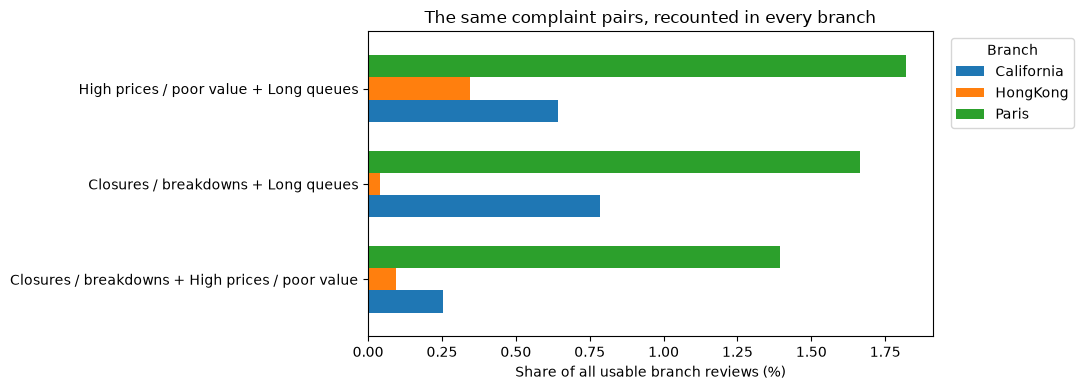

Frequent combinations; 30-review minimum retained


min_relative_support,Branch,At 0.5% support,At 1% support,At 2% support
,Disneyland_California,3,0,0
,Disneyland_HongKong,0,0,0
,Disneyland_Paris,4,3,0


Selected-rule check after excluding repeated review IDs


Branch,Rules before exclusion,Rules after exclusion,Rules lost,Rules added
Disneyland_California,0,0,0,0
Disneyland_HongKong,0,0,0,0
Disneyland_Paris,0,0,0,0


In [11]:
comparisons = helper.compare_branch_patterns(baskets_df, mining, **settings)
itemset_comparison = comparisons["itemset_comparison"]
rule_comparison = comparisons["rule_comparison"]

if not itemset_comparison.empty:
    pair_percentages = 100 * itemset_comparison.pivot(
        index="pattern", columns="Branch", values="relative_support"
    )
    pair_percentages.columns = [
        branch.replace("Disneyland_", "")
        for branch in pair_percentages.columns
    ]
    ax = pair_percentages.plot.barh(figsize=(11, 4), width=0.7)
    ax.set_title("The same complaint pairs, recounted in every branch")
    ax.set_xlabel("Share of all usable branch reviews (%)")
    ax.set_ylabel("")
    ax.legend(title="Branch", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

sensitivity_view = (
    comparisons["sensitivity"]
    .pivot(
        index="Branch", columns="min_relative_support", values="multi_itemsets"
    )
    .reset_index()
    .rename(
        columns={
            0.005: "At 0.5% support",
            0.01: "At 1% support",
            0.02: "At 2% support",
        }
    )
)
show_result(
    sensitivity_view, "Frequent combinations; 30-review minimum retained"
)
show_result(
    comparisons["duplicate_sensitivity"].rename(
        columns={
            "original_rules": "Rules before exclusion",
            "rules_without_repeated_ids": "Rules after exclusion",
            "removed_rules": "Rules lost",
            "new_rules": "Rules added",
        }
    ),
    "Selected-rule check after excluding repeated review IDs",
)


### 5.3 Sentiment Intensity Analysis

VADER sentiment intensity scoring was applied to prepared sentences or contrast clauses containing matched attractions, services, or complaint phrases. Capitalization, punctuation, and repaired negations were retained, and the resulting scores describe the surrounding wording rather than a whole-review sentiment label. Complaint-containing clauses include negative, neutral, and positive contexts, so a positive context does not automatically invalidate an explicit complaint match. The current analysis does not test whether compound sentiment scores align closely with the discrete 1-to-5 star ratings.

The attraction summary below first averages matched context scores within each review and then across reviews mentioning the attraction, so repeated mentions in one review do not give that review extra weight. Its mean scores and mixed-context counts provide a starting point for inspecting attraction mentions, although they do not establish that attractions buffer ratings or that operations cause dissatisfaction. A clause can mention several aspects, and dictionary matches may refer to a comparison with another park rather than an experience at the review's stated branch.

TF-IDF and VADER therefore provide different views of the text: TF-IDF identifies relatively weighted terms, while VADER describes the tone of matched contexts. We have not established positive and negative clusters, attraction-to-complaint sentiment ratios, or causal links between park size, visit duration, and satisfaction. Those claims would require additional analysis and human review of the matched passages.


In [12]:
# reuse the helper's extracted evidence rather than score the text again
evidence_quality = helper.analyze_evidence_quality(text_df, evidence)
unique_contexts = evidence["primary_complaints"].drop_duplicates(
    ["row_id", "segment_id"]
)
sentiment_counts = pd.crosstab(
    unique_contexts["Branch"], unique_contexts["context_sentiment"]
).reindex(columns=["negative", "neutral", "positive"], fill_value=0)
sentiment_view = 100 * sentiment_counts.div(
    sentiment_counts.sum(axis=1), axis=0
)
sentiment_view.insert(0, "Matched clauses", sentiment_counts.sum(axis=1))
show_result(
    sentiment_view.reset_index().rename(
        columns={
            "negative": "Negative (%)",
            "neutral": "Neutral (%)",
            "positive": "Positive (%)",
        }
    ),
    "Context of complaint-containing clauses; each clause counted once",
)
attraction_summary = (
    evidence["aspect_summary"]
    .loc[evidence["aspect_summary"]["aspect_type"].eq("attraction")]
    .sort_values("reviews", ascending=False)
)
show_result(
    attraction_summary[
        [
            "Branch",
            "aspect",
            "reviews",
            "mean_context_score",
            "mixed_context_reviews",
        ]
    ].rename(
        columns={
            "aspect": "Matched attraction",
            "reviews": "Mentioning reviews",
            "mean_context_score": "Mean context score (-1 to +1)",
            "mixed_context_reviews": "Reviews with both positive and negative context",
        }
    ),
    "Five most-mentioned branch-attraction combinations",
)


Context of complaint-containing clauses; each clause counted once


context_sentiment,Branch,Matched clauses,Negative (%),Neutral (%),Positive (%)
,Disneyland_California,4654,28.56,38.63,32.81
,Disneyland_HongKong,1493,24.58,41.53,33.89
,Disneyland_Paris,5578,35.66,32.97,31.37


Five most-mentioned branch-attraction combinations


Branch,Matched attraction,Mentioning reviews,Mean context score (-1 to +1),Reviews with both positive and negative context
Disneyland_California,Space Mountain,1564,0.18,29
Disneyland_Paris,Space Mountain,1353,0.20,27
Disneyland_Paris,Big Thunder Mountain,1188,0.15,27
Disneyland_California,Haunted Mansion,894,-0.13,19
Disneyland_California,It's a Small World,884,0.24,7


Showing 5 of 35 rows; the full table remains available.


### 5.4 Limitations, and Operational Recommendations

The complaint counts provide starting points for reviewing operational concerns, although no association rule passed all the chosen cutoffs. The recommendation helper selects the high prices or poor value and long queues pair for Paris, crowding for California, and long queues for Hong Kong. It uses a frequent single category when no pair qualifies, and it compares branch percentages with the pooled percentage in the other branches. Hong Kong's selected category is not more frequent than in the other branches combined, so it represents a common issue to inspect rather than a distinctive branch problem.

Several analytical and data-quality limitations must be considered when interpreting these findings. First, 2,613 review records (6.13%) lack valid Year_Month timestamp data, preventing longitudinal trend tracking for those specific entries, although their text content remains valid for cross-sectional mining. Second, Review_ID tracks individual review submissions rather than unique visitors, meaning repeat reviewers cannot be individually isolated. Finally, demographic skew in reviewer origin, such as United Kingdom residents accounting for 58.6% of Disneyland Paris reviews and United States residents making up 63.6% of California reviews, limits how broadly the findings can be generalized; these shares do not themselves demonstrate cultural differences in rating strictness or review length.

For Disneyland Paris, management could first examine price communication and the waiting experiences described in the matching reviews. For Disneyland California, the crowding evidence supports reviewing crowd movement at the cited locations, while Disneyland Hong Kong's queue complaints support comparing posted and observed waits. These are proposed checks rather than proven solutions, and they do not establish a need for pass-holder restrictions, land expansion, or attraction redesign. The phrase rules can miss or misinterpret complaints, so source reviews and the audit tables should be checked before decisions are made.


In [13]:
follow_up = helper.build_recommendations(
    text_df,
    baskets_df,
    mining,
    comparisons,
    evidence_quality["target_summary"],
)
recommendations = follow_up["recommendations"]
show_result(
    recommendations[
        [
            "Branch",
            "evidence_pair",
            "review_count",
            "review_pct",
            "other_review_pct",
            "gap_pp",
        ]
    ].rename(
        columns={
            "evidence_pair": "Selected pattern",
            "review_count": "Matching reviews",
            "review_pct": "This branch (%)",
            "other_review_pct": "Other branches (%)",
            "gap_pp": "Gap (percentage points)",
        }
    ),
    "Evidence behind the recommendations",
)
show_result(
    recommendations[["Branch", "proposed_follow_up"]].rename(
        columns={
            "proposed_follow_up": "Suggested evidence check",
        }
    ),
    "Proposed follow-up; confirm the source reviews before taking action",
)

# keep the report's complete results synchronized with the displayed tables
results.update({**mining, **comparisons, **evidence_quality, **follow_up})
results["validation"] = helper.validate_analysis(
    text_df, results, vector_results
)
print(f"Final computational checks passed: {len(results['validation'])}.")


Evidence behind the recommendations


Branch,Selected pattern,Matching reviews,This branch (%),Other branches (%),Gap (percentage points)
Disneyland_California,Crowding,763,3.93,2.32,1.61
Disneyland_HongKong,Long queues,661,6.88,10.46,-3.58
Disneyland_Paris,High prices / poor value + Long queues,248,1.82,0.54,1.28


Proposed follow-up; confirm the source reviews before taking action


Branch,Suggested evidence check
Disneyland_California,examine crowd movement and capacity management at the cited locations; first confirm that the comments describe related circumstances.
Disneyland_HongKong,compare posted and observed waits and inspect queue handling; first confirm that the comments describe related circumstances.
Disneyland_Paris,check price communication against the experience described and compare posted and observed waits and inspect queue handling; first confirm that the comments describe related circumstances.


Final computational checks passed: 9.


## References


- **information-retrieval.ipynb** and **information-retrieval[adlib].ipynb**: supplied class notebooks, adapted from Prof Christian Alis and revised by Leodegario Lorenzo II; used for the CountVectorizer workflow and sparse text representation.
- **07-information-retrieval.pdf**, slides 15–17: preprocessing, bag-of-words and TF-IDF concepts. Scikit-learn's smoothed IDF and normalization are stated explicitly because their numeric convention differs from the lecture's introductory formula.
- **Frequent Itemset Mining (3).ipynb**, prepared by Christian Alis: transaction sets, absolute and relative support, standard-library Apriori, and association rules with a single consequent and deterministic sorting. No retail-data conclusions or timing claims were transferred to this dataset.
- Hutto, C. J., and Gilbert, E. (2014). *VADER: A Parsimonious Rule-based Model for Sentiment Analysis of Social Media Text*. Used as a contextual sentiment baseline rather than a validated Disneyland aspect classifier.